Single allele groupped structue models.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd
import logomaker
import sys
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)
METHOD = "hmm_pomegranate"


 1. Read data

In [2]:
DATA_PATH = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/per_length_per_kfold_split/' # windows
# DATA_PATH = '/home/denklewer/Data/length_dependent_hmm/' #ubuntu
TARGET_PATH_TO_RESULTS = "experiment_results/single_allele_balanced_data_base_model_viterbi_playground/" #!CHANGE for bwv!

In [3]:
from data_reading_methods import get_available_alleles, read_data

ALLELES = get_available_alleles(DATA_PATH)

per_allele_per_kfold_per_length_binders_train = read_data(DATA_PATH, ALLELES, "train", "binders")
per_allele_per_kfold_per_length_binders_test = read_data(DATA_PATH, ALLELES, "test", "binders")
per_allele_per_kfold_per_length_non_binders_train = read_data(DATA_PATH, ALLELES, "train", "nonbinders")
per_allele_per_kfold_per_length_non_binders_test = read_data(DATA_PATH, ALLELES, "test", "nonbinders")

ALLELES

['HLA-A*01:01',
 'HLA-DPA1*01:03-DPB1*04:01',
 'HLA-A*03:01',
 'HLA-A*02:01',
 'HLA-DRB1*01:01',
 'HLA-DRB1*04:01',
 'HLA-B*27:05',
 'HLA-B*07:02']

In [4]:
def make_logo_for_data(binders_array, name):
    sns.set_theme(style="white")
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', flip_below=True)
    ww_logo.ax.set_title(f"{name}, {len(binders_array)}")

# 2. Prepare data and weithgs for training
## 2.1 Merge alleles into combinations

In [16]:
# combination_size = len(ALLELES)
# ALLELES = sorted(['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'
#                   ])
ALLELES = sorted([ 'HLA-A*03:01'])

# ALLELES = sorted(['HLA-DRB1*01:01', 'HLA-DPA1*01:03-DPB1*04:01'])
# ALLELES = sorted(['HLA-DRB1*01:01'])

combination_size = 1
TOTAL_SPLITS = 5
NUM_RUNS = 5
USE_WEIGHTS = True
# TARGET_LENGTHS= [13, 14, 15, 16, 17, 18]
properties_num = 12
# TARGET_LENGTHS= [15]
TARGET_LENGTHS= [9]
check_peptides = False

## Motif for train data

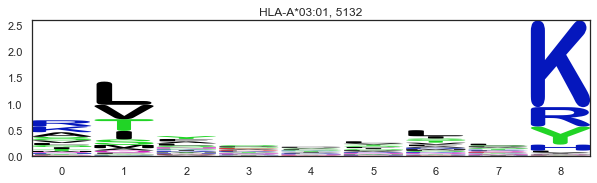

In [6]:
target_allele = ALLELES[0]
target_length = TARGET_LENGTHS[0]
peptides = per_allele_per_kfold_per_length_binders_train[target_allele][0][target_length]
make_logo_for_data(peptides, ALLELES[0])

# Get initial params based on decoy data

In [7]:
from aaindex.aaindex import aaindex
IMPORTANT_PROPERTIES_FROM_PAPER = [
    "GEIM800103",
    "OOBM770104",
    "QIAN880132",
    "PALJ810115",
    "OOBM850102",
    "NADH010106",
    "RADA880106",
    "QIAN880112",
    "WEBA780101",
    "QIAN880125",
    "JOND750101",
    "QIAN880124"
]
record_values = aaindex[IMPORTANT_PROPERTIES_FROM_PAPER[0]]['values']
transform_dicts = list()
for i in range (properties_num):
    transform_dicts.append(aaindex[IMPORTANT_PROPERTIES_FROM_PAPER[i]]['values'])


## Get decoy data

In [17]:
from mhcgnomes import parse
# decoy data
def defineOrganism(allele_name):
    parse_result = parse(allele_name)
    if parse_result.is_mouse:
        return "Mouse"
    elif parse_result.is_human:
        return "Human"
    else:
        print("organism not found")
        return None

def defineClass(allele_name):
    parse_result = parse(allele_name)
    if parse_result.has_mhc_class:
        if parse_result.is_class1:
            return 'I'
        elif parse_result.is_class2:
            return 'II'
        else:
            print("Not class I or class II???!")
    else:
        print("Result without class")
    return None

per_allele_decoy_peptides = dict()
for allele_name in ALLELES:
    organism =  defineOrganism(allele_name).lower()
    class_to_use = defineClass(allele_name)
    DECOY_DATA_PATH = f"D:\Google Drive\Work\ITMO\data\decoy\sampled_decoy_data_{organism}_class_{class_to_use}.csv"
    decoy_df =  pd.read_csv(DECOY_DATA_PATH)
    decoy_df['length'] = decoy_df['peptide'].str.len()
    per_allele_decoy_peptides[allele_name] = decoy_df.copy()[decoy_df['length'].isin(TARGET_LENGTHS)]['peptide'].values

peptides_for_analysis = np.unique(np.concatenate([value for key, value in per_allele_decoy_peptides.items()
                                                  if key in ALLELES]))

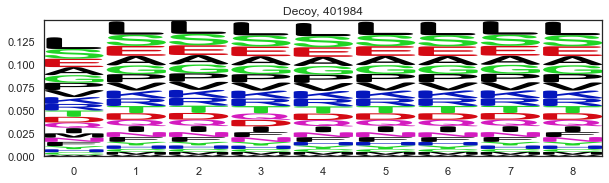

In [19]:
make_logo_for_data(peptides_for_analysis, "Decoy")

In [9]:
decoy_converted = np.array([np.array([tuple(transform_dict[aa] for transform_dict in transform_dicts) for aa in peptide]) for peptide in peptides_for_analysis])


KeyboardInterrupt: 

In [10]:
initial_params = list()
for i, transform_dict in enumerate(transform_dicts):
    print(f"prop {i}")
    decoy_converted = [transform_dict[aa] for peptide in peptides_for_analysis for aa in peptide]
    mean_value = np.mean(decoy_converted)
    std_value = np.std(decoy_converted)
    initial_params.append({"mean": mean_value,
                           "std": std_value})

del decoy_converted

prop 0
prop 1
prop 2
prop 3
prop 4
prop 5
prop 6
prop 7
prop 8
prop 9
prop 10
prop 11


In [11]:
initial_params

[{'mean': 1.0226856895950132, 'std': 0.4653982261707557},
 {'mean': -13.492930740535641, 'std': 3.3442222470331444},
 {'mean': 0.040244404449395574, 'std': 0.6320949271411154},
 {'mean': 0.9629247434843493, 'std': 0.38115475508954194},
 {'mean': 1.2665051637018603, 'std': 1.0097842601515845},
 {'mean': 12.562038652817934, 'std': 75.84359639951758},
 {'mean': 151.934175942203, 'std': 64.21684446974054},
 {'mean': -0.012586162261606727, 'std': 0.3578209384310855},
 {'mean': 0.8291743466938742, 'std': 0.1301220647293389},
 {'mean': -0.0075879992435045045, 'std': 0.2482830166138515},
 {'mean': 1.2540070221480026, 'std': 1.055255980380119},
 {'mean': -0.07532619992897722, 'std': 0.28518997926516815}]

# Transform data

In [12]:
from data_reading_methods import merge_per_allele_sets_into_combination_sets

per_allele_per_kfold_per_length_binders_train_old = per_allele_per_kfold_per_length_binders_train
per_allele_per_kfold_per_length_binders_test_old = per_allele_per_kfold_per_length_binders_test


if check_peptides:
    transform_dicts=None

per_allele_per_kfold_per_length_binders_train, per_allele_per_kfold_per_length_binders_test = merge_per_allele_sets_into_combination_sets(
    per_allele_per_kfold_per_length_binders_train, per_allele_per_kfold_per_length_binders_test,
    combination_size=combination_size,
    selected_alelles=ALLELES,
    total_splits=TOTAL_SPLITS,
    list_of_transform_dicts=transform_dicts
)
OLD_ALLELES = ALLELES
NEW_ALLELES = list(per_allele_per_kfold_per_length_binders_test.keys())
ALLELES = NEW_ALLELES

HLA-A*03:01
Length 8: HLA-A*03:01 - 93 
Length 9: HLA-A*03:01 - 5132 
Length 10: HLA-A*03:01 - 2184 
Length 11: HLA-A*03:01 - 691 
Length 12: HLA-A*03:01 - 202 
Length 13: HLA-A*03:01 - 98 
Length 14: HLA-A*03:01 - 31 
Length 15: HLA-A*03:01 - 18 
Length 16: HLA-A*03:01 - 12 
Length 17: HLA-A*03:01 - 5 
Length 18: HLA-A*03:01 - 4 


In [13]:
ALLELES

['HLA-A*03:01']

In [14]:
per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][9]

array([[[ 1.1300e+00, -1.3689e+01, -8.0000e-02, ..., -1.7000e-01,
          0.0000e+00, -4.7000e-01],
        [ 5.5000e-01, -1.2369e+01, -1.0000e-01, ...,  3.6000e-01,
          7.0000e-02,  2.7000e-01],
        [ 1.0800e+00, -2.0232e+01, -5.0000e-02, ..., -8.0000e-02,
          2.6700e+00,  6.0000e-02],
        ...,
        [ 1.2500e+00, -1.5728e+01, -5.4000e-01, ..., -2.6000e-01,
          2.1700e+00, -4.4000e-01],
        [ 1.2000e+00, -1.2480e+01,  7.1000e-01, ...,  3.0000e-02,
          9.0000e-02,  6.0000e-02],
        [ 2.0000e-01, -1.6225e+01, -4.0000e-01, ...,  4.0000e-02,
          8.5000e-01, -1.0000e-01]],

       [[ 2.0000e-01, -1.6225e+01, -4.0000e-01, ...,  4.0000e-02,
          8.5000e-01, -1.0000e-01],
        [ 6.4000e-01, -1.3867e+01, -8.6000e-01, ..., -1.8000e-01,
          1.8700e+00,  1.1000e-01],
        [ 1.0800e+00, -2.0232e+01, -5.0000e-02, ..., -8.0000e-02,
          2.6700e+00,  6.0000e-02],
        ...,
        [ 1.2700e+00, -1.5608e+01, -7.4000e-01, ..., -

## 2.2 Calculate counts of initial data (will be used to calculate weights further)

In [15]:
from data_reading_methods import extract_count_df, calculate_weights_based_on_length_counts

count_df_train = extract_count_df(per_allele_per_kfold_per_length_binders_train_old,
                                  selected_alleles=OLD_ALLELES,
                                  total_splits=TOTAL_SPLITS)
count_df_test = extract_count_df(per_allele_per_kfold_per_length_binders_test_old,
                                 selected_alleles=OLD_ALLELES,
                                 total_splits=TOTAL_SPLITS)


In [16]:
count_df_train.index.levels

FrozenList([['HLA-A*03:01'], [0, 1, 2, 3, 4], [8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18]])

## 2.3 Weights for data based on counts

In [17]:
per_allele_per_kfold_per_length_weights = calculate_weights_based_on_length_counts(count_df_train,
                                                                                   selected_alleles=ALLELES,
                                                                                   total_splits=TOTAL_SPLITS,
                                                                                   selected_lengths=TARGET_LENGTHS,
                                                                                   use_weights=USE_WEIGHTS)

Total data length for split 0 is 8209
Weights for lentgh 9 are {'HLA-A*03:01': 1.5995713172252533}
Weights for lentgh 10 are {'HLA-A*03:01': 3.7586996336996337}
Weights for lentgh 11 are {'HLA-A*03:01': 11.879884225759769}
Weights for lentgh 12 are {'HLA-A*03:01': 40.63861386138614}
Total data length for split 1 is 8209
Weights for lentgh 9 are {'HLA-A*03:01': 1.5995713172252533}
Weights for lentgh 10 are {'HLA-A*03:01': 3.7586996336996337}
Weights for lentgh 11 are {'HLA-A*03:01': 11.879884225759769}
Weights for lentgh 12 are {'HLA-A*03:01': 40.63861386138614}
Total data length for split 2 is 8209
Weights for lentgh 9 are {'HLA-A*03:01': 1.5995713172252533}
Weights for lentgh 10 are {'HLA-A*03:01': 3.7586996336996337}
Weights for lentgh 11 are {'HLA-A*03:01': 11.879884225759769}
Weights for lentgh 12 are {'HLA-A*03:01': 40.63861386138614}
Total data length for split 3 is 8209
Weights for lentgh 9 are {'HLA-A*03:01': 1.5995713172252533}
Weights for lentgh 10 are {'HLA-A*03:01': 3.75869

## Transform to properties

# 2. Train HMMS
## 2.1 Code for HMM
### 2.1.1 Training code

In [18]:
from hmm_logic_methods import train_model, save_model, add_more_states_and_reset_transitions, init_grouped_structure_model_joiners_and_cycles



## 2.2 Train
### 2.2.1 Define treshold

In [19]:
stop_threshold = 0
cutoff = 0.00005
per_symbol_portion = -5
for target_length in TARGET_LENGTHS:
    target_length_for_training = target_length
    train_size = len(per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][target_length])
    ## Stop threshold Hardcoded here
    stop_threshold +=  abs(cutoff * train_size * per_symbol_portion  * target_length_for_training)
stop_threshold = stop_threshold / len(TARGET_LENGTHS)
stop_threshold

4.8783125

### 2.2.2 Prepare  initial grouped structure models

In [20]:
# Training params
algorithm = 'baum-welch'

params = dict()


# params['st'] = 7
# params['multiple_check_input'] = False
# params['alg'] = algorithm
# params['min_iters'] = 30
# params['max_iters'] = 65
# params['stop_threshold'] = stop_threshold
# params['emission_pseudocount'] = 1
# params['transition_pseudocount'] = 0
# params['verbose'] = True
# params['lr_decay'] = 0
# params['edge_inertia'] = 0.25
# params['distribution_inertia'] = 0
# params['groups'] = 7
# params['states_per_group'] = 1
# params['use_pseudocount'] = True

params['st'] = 7
params['multiple_check_input'] = False
params['alg'] = algorithm
params['min_iters'] = 30
params['max_iters'] = 65
params['stop_threshold'] = stop_threshold
params['emission_pseudocount'] = 0
params['transition_pseudocount'] = 0
params['verbose'] = True
params['lr_decay'] = 0
params['edge_inertia'] = 0
params['distribution_inertia'] = 0
params['groups'] = 7
params['states_per_group'] = 1
params['use_pseudocount'] = False
# Class 1 params
params['self_cycle'] = True
params['start_cycle'] = False
params['end_cycle'] = False

params['freeze_distr'] = True # wether to freeze start and end cycle distributions
params['cycle_pseudocount'] = 1



assert params['st'] % params['groups'] == 0
assert params['st'] % params['states_per_group'] == 0
assert params['st'] == params['groups'] *  params['states_per_group']

params_for_string = {key: value for key, value in params.items() if key in ['st', 'alg', 'min_iters']}
params_string = "-".join([f"{value}-{key}" for key, value in params_for_string.items()])
lengths_string = "-".join(map(str, TARGET_LENGTHS))



In [21]:
from pomegranate import *
import json
import numpy as np
import pandas as pd
from pomegranate.io import BatchedDataGenerator, SequenceGenerator
from hmm_visualization_methods import convert_graph_to_good_format
import networkx as nx
from tqdm import tqdm
from collections import defaultdict
from pomegranate import IndependentComponentsDistribution

MINUS_INF_CONSTANT = -20
MINUS_INF_CONSTANT_NORMALIZED = -0.5

def init_distribution(amino_acids=None, initial_means=None, initial_stds=None, discrete_distribution=False):
    amino_acids_list = list(amino_acids)
    if not discrete_distribution:
        components_d  = list()
        for i in range(len(initial_params)):
            mean_value = initial_means[i]
            std_value = initial_stds[i]
            d = NormalDistribution(mean_value, std_value)
            components_d.append(d)
        total_d = IndependentComponentsDistribution(components_d)
    else:
        d_dict = {key: prob for key, prob in zip(amino_acids_list, np.random.default_rng().uniform(0, 1, size=len(amino_acids_list)))}
        d_sum = sum(d_dict.values())
        d_dict = {key: value/d_sum for key, value in d_dict.items()}
        total_d = DiscreteDistribution(d_dict)
    return total_d


def init_grouped_structure_model_joiners_and_cycles_here(
        states_per_group=5, # may be int or list of numbers for each group
        number_of_groups=5,
        amino_acids="ACDEFGHIKLMNPQRSTVWY",
        freeze_distr=False,
        CYCLE_PSEUDOCOUNT=1,
        initial_params=None,
        start_cycle=True,
        end_cycle=True,
        self_cycles=False,
        discrete_distribution=False
):

    INTRAGROUP_WEIGHT = 1
    INTERGROUP_WEIGHT = 1

    START_WEIGHT = 1
    TO_CYCLE_WEIGHT = 3
    IN_CYCLE_WEIGHT = 5
    if start_cycle or end_cycle:
        TO_JOINER_WEIGHT = 5 #just to make transitions even inside groups
    else:
        TO_JOINER_WEIGHT = 1
    END_WEIGHT = 1
    FROM_CYCLE_WEIGHT = 1
    amino_acids_list = list(amino_acids)

    joiner_positions = {0: [0], 1: [1]}
    number_of_joiners = sum(len(positions) for positions in joiner_positions.values())
    number_of_groups = number_of_groups

    if type(states_per_group) == list:
        assert number_of_groups == len(states_per_group), f"Number of groups is expected to be {number_of_groups} but got {len(states_per_group)} in a list of states per group"
    else:
        states_per_group = [states_per_group for i in range(number_of_groups)]
    distributions = list()


    mean_values = list()
    stds = list()
    for initial_distr_params in initial_params:
        mean_values.append(initial_distr_params['mean'])
        stds.append(initial_distr_params['std'])
    print(f"mean values : {mean_values}")
    print(f"std values : {stds}")

    # initialize group states
    for group_number in range(number_of_groups):
        states_in_group = states_per_group[group_number]
        for state_num in range(states_in_group):
            total_d = init_distribution(amino_acids=amino_acids,
                                        initial_means=mean_values,
                                        initial_stds=stds,
                                        discrete_distribution=discrete_distribution)
            distributions.append(total_d)
    #initialize joiner states (random here)
    joiner_label_to_index_in_model = dict()
    for joiner_name in range(number_of_joiners):
        # d = DiscreteDistribution(
        #     {key: prob for key, prob in zip(amino_acids_list, np.random.uniform(0, 1, size=len(amino_acids_list)))})
        total_d = init_distribution(amino_acids=amino_acids,
                                    initial_means=mean_values,
                                    initial_stds=stds,
                                    discrete_distribution=discrete_distribution)
        joiner_label_to_index_in_model[joiner_name] = len(distributions)
        distributions.append(total_d)
    # initialize cycle states
    if start_cycle:
        start_d = init_distribution(amino_acids=amino_acids,
                                    initial_means=mean_values,
                                    initial_stds=stds,
                                    discrete_distribution=discrete_distribution)
        if freeze_distr:
            start_d.freeze()
        distributions.append(start_d)
    if end_cycle:
        end_d = init_distribution(amino_acids=amino_acids,
                                  initial_means=mean_values,
                                    initial_stds=stds,
                                    discrete_distribution=discrete_distribution)
        if freeze_distr:
            end_d.freeze()
        distributions.append(end_d)


    # print("joiners positions", joiner_label_to_index_in_model)

    num_states = sum(states_per_group) + number_of_joiners +  int(start_cycle) + int(end_cycle) # groups, joiners, 2 cycles
    assert num_states == len(distributions)
    print(f"states will be groups:{sum(states_per_group)} + joiners:{number_of_joiners} + start/end cycles:{ int(start_cycle) + int(end_cycle)}")

    state_names = ["s{:03d}".format(i) for i in range(num_states)]
    transition_matrix = numpy.zeros((num_states, num_states))

    # start probabilities
    first_joiners = set(joiner_label_to_index_in_model[label] for label in joiner_positions[0])
    last_joiners = set(joiner_label_to_index_in_model[label] for label in joiner_positions[max(joiner_positions.keys())])
    # connect start cycle to the first joiners
    start_cycle_idx = sum(states_per_group) + number_of_joiners
    end_cycle_idx = start_cycle_idx + 1

    # start only for first cycle and first joiner
    start_probabilities = [START_WEIGHT
                           if i == start_cycle_idx or i in first_joiners
                           else 0
                           for i in range(num_states)]


    # do not restrict ending in multiple states, so probs are equal to transitions inside

    end_probabilities = [END_WEIGHT
                         if i == end_cycle_idx or i in last_joiners
                         else 0
                         for i in range(num_states)]

    #  start cycle transitions
    if start_cycle:
        for joiner_idx in first_joiners:
            transition_matrix[start_cycle_idx][joiner_idx] = FROM_CYCLE_WEIGHT # from cycle to joiners
        transition_matrix[start_cycle_idx][start_cycle_idx] = IN_CYCLE_WEIGHT #cycle
        start_probabilities[start_cycle_idx] = TO_CYCLE_WEIGHT #from start to cycle

    # connect last joiners to last cycle
    if end_cycle:
        for joiner_idx in last_joiners:
            transition_matrix[joiner_idx][end_cycle_idx] = TO_CYCLE_WEIGHT
        transition_matrix[end_cycle_idx][end_cycle_idx] = IN_CYCLE_WEIGHT


    # Transitions inside groups
    for group_number in range(number_of_groups):
        states_in_group = states_per_group[group_number]
        for i in range(states_in_group):
            state_num_from = sum(states_per_group[:group_number]) + i
            # fill transitions inside each group with INTRAGROUP_WEIGHT
            for j in range(states_in_group):

                state_num_to =  sum(states_per_group[:group_number]) + j
                if state_num_from != state_num_to:
                    transition_matrix[state_num_from][state_num_to] = INTRAGROUP_WEIGHT
            if self_cycles:
                transition_matrix[state_num_from][state_num_from] = INTRAGROUP_WEIGHT
            # transition to next group
            if group_number != number_of_groups - 1:
                for j in range(states_in_group):
                    state_num_to = sum(states_per_group[:group_number+1]) + j
                    transition_matrix[state_num_from][state_num_to] = INTERGROUP_WEIGHT



    # connect first joiner to first group
    for joiner_index in first_joiners:
        group_number = 0
        state_num_from = joiner_index
        states_in_group =  states_per_group[group_number]
        for j in range(states_in_group):
            state_num_to = sum(states_per_group[:group_number]) + j
            transition_matrix[state_num_from][state_num_to] = INTERGROUP_WEIGHT

    # connect last group to the last joiner
    for joiner_index in last_joiners:
        group_number = number_of_groups -1
        state_num_to = joiner_index
        states_in_group =  states_per_group[group_number]
        for j in range(states_in_group):
            state_num_from = sum(states_per_group[:group_number]) + j
            transition_matrix[state_num_from][state_num_to] = TO_JOINER_WEIGHT
    model_name = 'grouped_model'


    # assert sum(start_probabilities) == len(joiner_positions[0])* START_WEIGHT + TO_CYCLE_WEIGHT, start_probabilities
    # assert sum(end_probabilities) ==  (len(joiner_positions[max(joiner_positions.keys())]) + 1)  * END_WEIGHT, end_probabilities + list(last_joiners)

    model = HiddenMarkovModel.from_matrix(
        name=model_name,
        transition_probabilities=transition_matrix,
        starts=start_probabilities,
        distributions=distributions,
        ends=end_probabilities,
        state_names=state_names,
        verbose=True)
    # Update created model with specific pseudocounts
    if start_cycle:
        model.add_transition(model.states[start_cycle_idx], model.states[start_cycle_idx], IN_CYCLE_WEIGHT, pseudocount=CYCLE_PSEUDOCOUNT)
        model.add_transition(model.start, model.states[start_cycle_idx], IN_CYCLE_WEIGHT, pseudocount=CYCLE_PSEUDOCOUNT)
        for joiner_idx in first_joiners:
            model.add_transition(model.states[start_cycle_idx], model.states[joiner_idx], IN_CYCLE_WEIGHT, pseudocount=CYCLE_PSEUDOCOUNT)
    if end_cycle:
        model.add_transition(model.states[end_cycle_idx], model.states[end_cycle_idx], IN_CYCLE_WEIGHT, pseudocount=CYCLE_PSEUDOCOUNT)
        model.add_transition(model.states[end_cycle_idx],model.end, IN_CYCLE_WEIGHT, pseudocount=CYCLE_PSEUDOCOUNT)
        for joiner_idx in last_joiners:
            model.add_transition(model.states[joiner_idx], model.states[end_cycle_idx], IN_CYCLE_WEIGHT, pseudocount=CYCLE_PSEUDOCOUNT)


        # model.add_transition(model.states[end_cycle_idx], model.states[end_cycle_idx], IN_CYCLE_WEIGHT, pseudocount=CYCLE_PSEUDOCOUNT)

    model.bake(verbose=True)
    return model

In [22]:

model = init_grouped_structure_model_joiners_and_cycles_here(
    states_per_group=int(params['states_per_group']),
    number_of_groups=params['groups'],
    freeze_distr= params['freeze_distr'],
    CYCLE_PSEUDOCOUNT=params['cycle_pseudocount'] ,
    initial_params=initial_params,
    start_cycle=params['start_cycle'],
    end_cycle=params['end_cycle'],
    self_cycles=params['self_cycle'],
    discrete_distribution=check_peptides)


mean values : [1.0226856895950132, -13.492930740535641, 0.040244404449395574, 0.9629247434843493, 1.2665051637018603, 12.562038652817934, 151.934175942203, -0.012586162261606727, 0.8291743466938742, -0.0075879992435045045, 1.2540070221480026, -0.07532619992897722]
std values : [0.4653982261707557, 3.3442222470331444, 0.6320949271411154, 0.38115475508954194, 1.0097842601515845, 75.84359639951758, 64.21684446974054, 0.3578209384310855, 0.1301220647293389, 0.2482830166138515, 1.055255980380119, 0.28518997926516815]
states will be groups:7 + joiners:2 + start/end cycles:0
grouped_model : s000 summed to 2.0, normalized to 1.0
grouped_model : s001 summed to 2.0, normalized to 1.0
grouped_model : s002 summed to 2.0, normalized to 1.0
grouped_model : s003 summed to 2.0, normalized to 1.0
grouped_model : s004 summed to 2.0, normalized to 1.0
grouped_model : s005 summed to 2.0, normalized to 1.0
grouped_model : s006 summed to 2.0, normalized to 1.0


In [23]:
with open('model.png', 'w+') as f:
    model.plot(file=f, crop_zero=True, rotation=90, rotate=90)

In [24]:
from hmm_visualization_methods import *
plot_distributions_for_states(model,"test/", horizontal=False, discrete=check_peptides, initial_params=initial_params)

In [25]:
make_pyviz_graph(model, "test/", precision=3)

Converting graph for model (grouped_model) (Delete zero edges)


<class 'pyvis.network.Network'> |N|=11 |E|=17

In [26]:
model.states[0]

{
    "class" : "State",
    "distribution" : {
        "class" : "Distribution",
        "name" : "IndependentComponentsDistribution",
        "parameters" : [
            [
                {
                    "class" : "Distribution",
                    "name" : "NormalDistribution",
                    "parameters" : [
                        1.0226856895950132,
                        0.4653982261707557
                    ],
                    "frozen" : false
                },
                {
                    "class" : "Distribution",
                    "name" : "NormalDistribution",
                    "parameters" : [
                        -13.492930740535641,
                        3.3442222470331444
                    ],
                    "frozen" : false
                },
                {
                    "class" : "Distribution",
                    "name" : "NormalDistribution",
                    "parameters" : [
                        0.0402444044

In [27]:
transform_dicts

[{'-': 0,
  'A': 1.55,
  'C': 1.44,
  'D': 1.55,
  'E': 1.67,
  'F': 0.4,
  'G': 0.59,
  'H': 1.21,
  'I': 1.27,
  'K': 1.2,
  'L': 1.25,
  'M': 1.37,
  'N': 1.2,
  'P': 0.21,
  'Q': 1.13,
  'R': 0.2,
  'S': 1.01,
  'T': 0.55,
  'V': 0.64,
  'W': 1.86,
  'Y': 1.08},
 {'-': 0,
  'A': -9.475,
  'C': -12.21,
  'D': -12.144,
  'E': -13.815,
  'F': -20.504,
  'G': -7.592,
  'H': -17.55,
  'I': -15.608,
  'K': -12.366,
  'L': -15.728,
  'M': -15.704,
  'N': -12.48,
  'P': -11.893,
  'Q': -13.689,
  'R': -16.225,
  'S': -10.518,
  'T': -12.369,
  'V': -13.867,
  'W': -26.166,
  'Y': -20.232},
 {'-': 0,
  'A': -0.27,
  'C': 0.0,
  'D': 0.54,
  'E': -0.12,
  'F': -0.47,
  'G': 1.14,
  'H': 0.18,
  'I': -0.74,
  'K': 0.45,
  'L': -0.54,
  'M': -0.76,
  'N': 0.71,
  'P': 1.4,
  'Q': -0.08,
  'R': -0.4,
  'S': 0.4,
  'T': -0.1,
  'V': -0.86,
  'W': -0.46,
  'Y': -0.05},
 {'-': 0,
  'A': 0.91,
  'C': 0.5,
  'D': 0.9,
  'E': 0.53,
  'F': 0.37,
  'G': 1.61,
  'H': 1.08,
  'I': 0.36,
  'K': 1.27,
  'L

{'-': 0.07665405698923297, 'W': 0.16990423077141326, 'R': 0.17970061402813706, 'P': 0.18661430535876639, 'E': 0.3258383290945884}
{'-': 3.481119932342887e-05, 'W': 9.083322885894281e-05, 'F': 0.013249827959213622, 'Y': 0.01566128987359364, 'G': 0.025149192178561614}
{'P': 0.06241000403086552, 'G': 0.13893122350069995, 'V': 0.22890939109291614, 'M': 0.2831933704566641, 'I': 0.2946202585650268}
{'-': 0.043042212563921586, 'P': 0.23685290702362796, 'G': 0.24772609073339685, 'I': 0.2995442639540725, 'F': 0.31212982650674453}
{'W': 1.3868366013470535e-08, 'D': 0.04996488534868192, 'Y': 0.14362479070278356, '-': 0.17992305883189855, 'N': 0.18962425224802812}
{'C': 0.00010797943927799551, 'W': 0.0015861928836357073, 'P': 0.001647616475268693, 'F': 0.0020381750761557034, 'V': 0.0020381750761557034}
{'-': 0.00037820429479471076, 'P': 0.00037820429479471076, 'W': 0.0010945034766335962, 'G': 0.0018779303649936086, 'R': 0.0019174491550102907}
{'P': 0.07693919868974305, 'L': 0.2336516146947898, 'K'

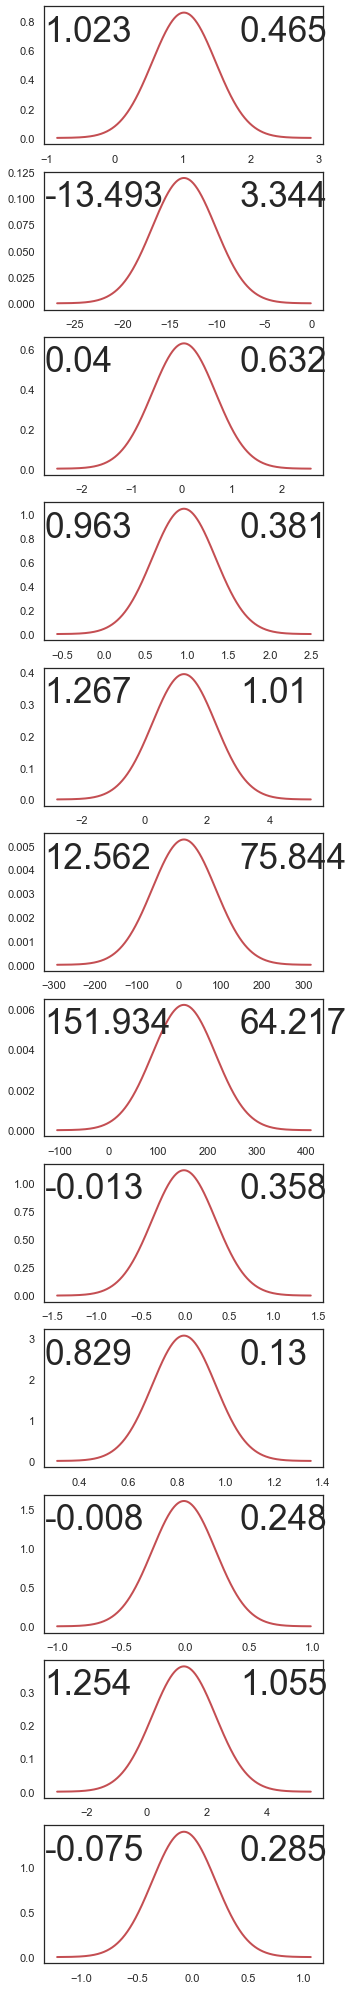

In [28]:
list_of_dists = model.states[0].distribution.parameters[0]
fig, axes = plt.subplots(ncols=1, nrows=len(list_of_dists), figsize=(5, len(list_of_dists)* 3))
for i, distr in enumerate(list_of_dists):

    distr_params = distr.parameters
    mean_value = distr_params[0]
    std_value = distr_params[1]
    x = np.linspace(mean_value-4*std_value, mean_value+4*std_value, 1000)
    y= norm.pdf(x, loc=mean_value, scale=std_value)
    axes[i].plot(x, y, 'r', lw=2, label=f'pdf')
    axes[i].text(0.0, 0.75, f'{np.round(mean_value,3)}', fontsize=35, transform=axes[i].transAxes)
    axes[i].text(0.7, 0.75, f'{np.round(std_value,3)}', fontsize=35, transform=axes[i].transAxes)
    transform_dict = transform_dicts[i]
    prob_dict = {aa: distr.probability(value) for aa, value in transform_dict.items()}
    print(dict(sorted(prob_dict.items(), key=lambda item:item[1])[:5]))

print(f"mean_value was {mean_value}")

In [248]:
model.states[0].distribution.parameters[0][2].parameters

[0.040244404449395574, 0.6320949271411154]

In [249]:
peptides =  per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][12]
peptide = per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][9][0]

In [250]:
TARGET_LENGTHS

[9, 10, 11, 12]

In [251]:
peptide

array([[ 1.1300e+00, -1.3689e+01, -8.0000e-02,  1.0600e+00,  1.4900e+00,
        -6.7000e+01,  1.7770e+02, -2.7000e-01,  8.2000e-01, -1.7000e-01,
         0.0000e+00, -4.7000e-01],
       [ 5.5000e-01, -1.2369e+01, -1.0000e-01,  8.7000e-01,  1.0900e+00,
         7.9000e+01,  1.4210e+02, -1.6000e-01,  9.2000e-01,  3.6000e-01,
         7.0000e-02,  2.7000e-01],
       [ 1.0800e+00, -2.0232e+01, -5.0000e-02,  1.2400e+00, -1.7000e-01,
         2.7000e+01,  2.3990e+02,  1.1000e-01,  4.9000e-01, -8.0000e-02,
         2.6700e+00,  6.0000e-02],
       [ 1.5500e+00, -1.2144e+01,  5.4000e-01,  9.0000e-01,  3.3200e+00,
         4.5000e+01,  1.4260e+02, -3.2000e-01,  8.7000e-01,  1.1000e-01,
         6.6000e-01,  1.3000e-01],
       [ 1.8600e+00, -2.6166e+01, -4.6000e-01,  1.1000e+00, -4.6500e+00,
         1.3000e+02,  2.7160e+02,  3.2000e-01,  2.0000e-01, -1.0000e-02,
         3.7700e+00, -8.0000e-02],
       [ 5.5000e-01, -1.2369e+01, -1.0000e-01,  8.7000e-01,  1.0900e+00,
         7.9000e+01,  

In [252]:
model.log_probability(peptide)

-201.41318609948144

In [253]:
# allele_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][target_length] for target_length in TARGET_LENGTHS])
# ten_mer = allele_peptides[12]
# print(ten_mer, len(ten_mer))
#prob, path = model.viterbi(ten_mer)
#print([item[0] for item in path])
# sixteen_mer = peptide_properties[8900]
# print(sixteen_mer, len(sixteen_mer))

In [254]:
#pd.DataFrame(model.forward(sixteen_mer))

In [255]:
#pd.DataFrame(model.forward_backward(sixteen_mer)[1])

In [256]:
#pd.DataFrame(model.forward_backward(ten_mer)[1])

In [257]:
#ten_mer

In [258]:
#state_sums = [sum(state.distribution.parameters[0].values()) for state in model.states[:-2]]
# assert np.isclose(sum(state_sums), len(state_sums))

## Prepare models

In [29]:
per_allele_per_run_per_split_prepared_models = dict()
for allele_name in ALLELES:
    target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')
    per_allele_per_run_per_split_prepared_models[allele_name] = dict()
    for run_num in range(NUM_RUNS):
        per_allele_per_run_per_split_prepared_models[allele_name][run_num] = dict()
        for split_num in range(TOTAL_SPLITS):
            # prepared_model  = init_grouped_structure_model(states_per_group=int(params['st']/params['groups']), number_of_groups=params['groups'])
            prepared_model = init_grouped_structure_model_joiners_and_cycles_here(
                states_per_group=int(params['states_per_group']),
                number_of_groups=params['groups'],
                CYCLE_PSEUDOCOUNT=params['cycle_pseudocount'],
                freeze_distr=params['freeze_distr'],
                initial_params=initial_params,
                start_cycle=params['start_cycle'],
                end_cycle=params['end_cycle'],
                self_cycles=params['self_cycle'],
                discrete_distribution=check_peptides
            )


            prepared_model.name = f'{run_num}_run-{lengths_string}-{params_string}_model-{target_allele_name}-{split_num}'
            per_allele_per_run_per_split_prepared_models[allele_name][run_num][split_num] = prepared_model

mean values : [1.0226856895950132, -13.492930740535641, 0.040244404449395574, 0.9629247434843493, 1.2665051637018603, 12.562038652817934, 151.934175942203, -0.012586162261606727, 0.8291743466938742, -0.0075879992435045045, 1.2540070221480026, -0.07532619992897722]
std values : [0.4653982261707557, 3.3442222470331444, 0.6320949271411154, 0.38115475508954194, 1.0097842601515845, 75.84359639951758, 64.21684446974054, 0.3578209384310855, 0.1301220647293389, 0.2482830166138515, 1.055255980380119, 0.28518997926516815]
states will be groups:7 + joiners:2 + start/end cycles:0
grouped_model : s000 summed to 2.0, normalized to 1.0
grouped_model : s001 summed to 2.0, normalized to 1.0
grouped_model : s002 summed to 2.0, normalized to 1.0
grouped_model : s003 summed to 2.0, normalized to 1.0
grouped_model : s004 summed to 2.0, normalized to 1.0
grouped_model : s005 summed to 2.0, normalized to 1.0
grouped_model : s006 summed to 2.0, normalized to 1.0
mean values : [1.0226856895950132, -13.49293074

In [260]:
# cycle_state = prepared_model.states[27]
# start = prepared_model.states[29]
# prepared_model.graph.edges()[cycle_state, cycle_state]

## Do training

In [30]:
%%time

per_name_models = dict()
per_allele_per_run_per_split_new_histories = dict()
for allele_name in ALLELES:
    per_allele_per_run_per_split_new_histories[allele_name] = dict()
    for run_num in range(NUM_RUNS):
        print(f"run {run_num}")
        per_kfold_per_length_data = per_allele_per_kfold_per_length_binders_train[allele_name]
        per_kfold_per_length_weights = per_allele_per_kfold_per_length_weights[allele_name]


        models, histories = train_model(allele_name=allele_name,
                                        per_kfold_per_length_data=per_kfold_per_length_data,
                                        per_kfold_per_length_weights_for_data=per_kfold_per_length_weights,
                                        target_lengths=TARGET_LENGTHS,
                                        multiple_check_input=params['multiple_check_input'],
                                        algorithm=params['alg'],
                                        verbose=params['verbose'],
                                        per_kfold_per_length_test_data=per_allele_per_kfold_per_length_binders_test[allele_name],
                                        stop_threshold=params['stop_threshold'],
                                        min_iterations= params['min_iters'],
                                        max_iterations=params['max_iters'],
                                        prepared_models=per_allele_per_run_per_split_prepared_models[allele_name][run_num],
                                        emission_pseudocount=params['emission_pseudocount'],
                                        transition_pseudocount=params['transition_pseudocount'],
                                        edge_inertia=params['edge_inertia'],
                                        distribution_inertia=params['distribution_inertia'],
                                        lr_decay=params['lr_decay'],
                                        use_pseudocount=params['use_pseudocount'])
        
        per_allele_per_run_per_split_prepared_models[allele_name][run_num] = models
        per_allele_per_run_per_split_new_histories[allele_name][run_num] = histories
        # per_allele_per_run_per_split_models[allele_name][run_num] = models
        for split_num, model in models.items():
            per_name_models[model.name] = model
        # save models
        for split_num, model in models.items():
            history = histories[split_num]
            save_model(TARGET_PATH_TO_RESULTS, model,history)
        break



run 0
split 0
train size 8209
Shuffling for fairness 
Simple training: Train Length 8209, init_batch_size None
Use pseudocount is False
[1] Improvement: 502746.36512042023	Time (s): 2.57
[2] Improvement: 80030.43666057009	Time (s): 3.029
[3] Improvement: 28789.587399733253	Time (s): 2.715
[4] Improvement: 16212.381185268983	Time (s): 2.44
[5] Improvement: 7050.213840841316	Time (s): 2.993
[6] Improvement: 2116.2969579864293	Time (s): 2.417
[7] Improvement: 1029.3820551196113	Time (s): 2.353
[8] Improvement: 1139.8226609090343	Time (s): 3.087
[9] Improvement: 946.2777653886005	Time (s): 3.025
[10] Improvement: 342.03950142953545	Time (s): 2.375
[11] Improvement: 92.4383712746203	Time (s): 2.76
[12] Improvement: 38.02916574943811	Time (s): 3.093
[13] Improvement: 16.61197487823665	Time (s): 2.269
[14] Improvement: 7.85406035464257	Time (s): 2.26
[15] Improvement: 4.684419536031783	Time (s): 2.993
[16] Improvement: 5.227656044997275	Time (s): 2.513
[17] Improvement: 13.63929938338697	Time

In [31]:
from hmm_visualization_methods import *

In [32]:
%%time

for i, model in enumerate(per_name_models.values()):
    print(i)
    # with open(f"{TARGET_PATH_TO_RESULTS}{model.name}/state_graph.png", 'w+') as f:
    #     model.plot(file=f, crop_zero=False)
    with open(f"{TARGET_PATH_TO_RESULTS}{model.name}/state_graph_cropped.png", 'w+') as f:
        model.plot(file=f, crop_zero=True)

0
Wall time: 112 ms


In [33]:
%%time

for i, model in enumerate(per_name_models.values()):
    plot_distributions_for_states(model,TARGET_PATH_TO_RESULTS, horizontal=False, discrete=check_peptides, initial_params=initial_params)
    print(i)

0
Wall time: 19.6 s


In [34]:
from hmm_visualization_methods import *
per_name_pyviz = dict()
for name, model in per_name_models.items():
    per_name_pyviz[name] = make_pyviz_graph(model, TARGET_PATH_TO_RESULTS, precision=3)

Converting graph for model (0_run-9-10-11-12-7-st-baum-welch-alg-30-min_iters_model-HLA_A_03_01-0) (Delete zero edges)


## Check distrs

In [106]:
transform_dicts[0]

{'-': 0,
 'A': 1.55,
 'C': 1.44,
 'D': 1.55,
 'E': 1.67,
 'F': 0.4,
 'G': 0.59,
 'H': 1.21,
 'I': 1.27,
 'K': 1.2,
 'L': 1.25,
 'M': 1.37,
 'N': 1.2,
 'P': 0.21,
 'Q': 1.13,
 'R': 0.2,
 'S': 1.01,
 'T': 0.55,
 'V': 0.64,
 'W': 1.86,
 'Y': 1.08}

In [44]:
model.states[0].name

's000'

scale 0.1706887571790416
before {'S': 0.8568878906074878, 'Y': 0.850730580475376, 'Q': 0.8347177435877203, 'K': 0.7971955938826178, 'N': 0.7971955938826178}
after {'Y': 1.362754919806546, 'Q': 1.3576358806872932, 'S': 1.3041753457131595, 'K': 1.285656859380962, 'N': 1.285656859380962}
scale 0.020356709735367382
before {'Q': 0.11908814063492529, 'E': 0.11874105947771278, 'V': 0.11854904751305831, 'N': 0.11394449933750077, 'T': 0.11274258971900107}
after {'Q': 0.1620887574304928, 'E': 0.1610685629441237, 'V': 0.16052555894970297, 'N': 0.15054309055623688, 'T': 0.14771090955934793}
scale 0.15335111779070743
before {'-': 0.629865065696148, 'C': 0.629865065696148, 'Y': 0.6247432444510039, 'Q': 0.6198257668848292, 'H': 0.6159033445895306}
after {'S': 1.1712697279743938, 'H': 1.144734465029915, 'K': 1.1045794177221098, 'D': 0.9364730657692047, '-': 0.799304646808363}
scale 0.26186433092615957
before {'A': 1.036625885944851, 'D': 1.0325009427162208, 'T': 1.0160195127256044, 'Q': 1.013265692853

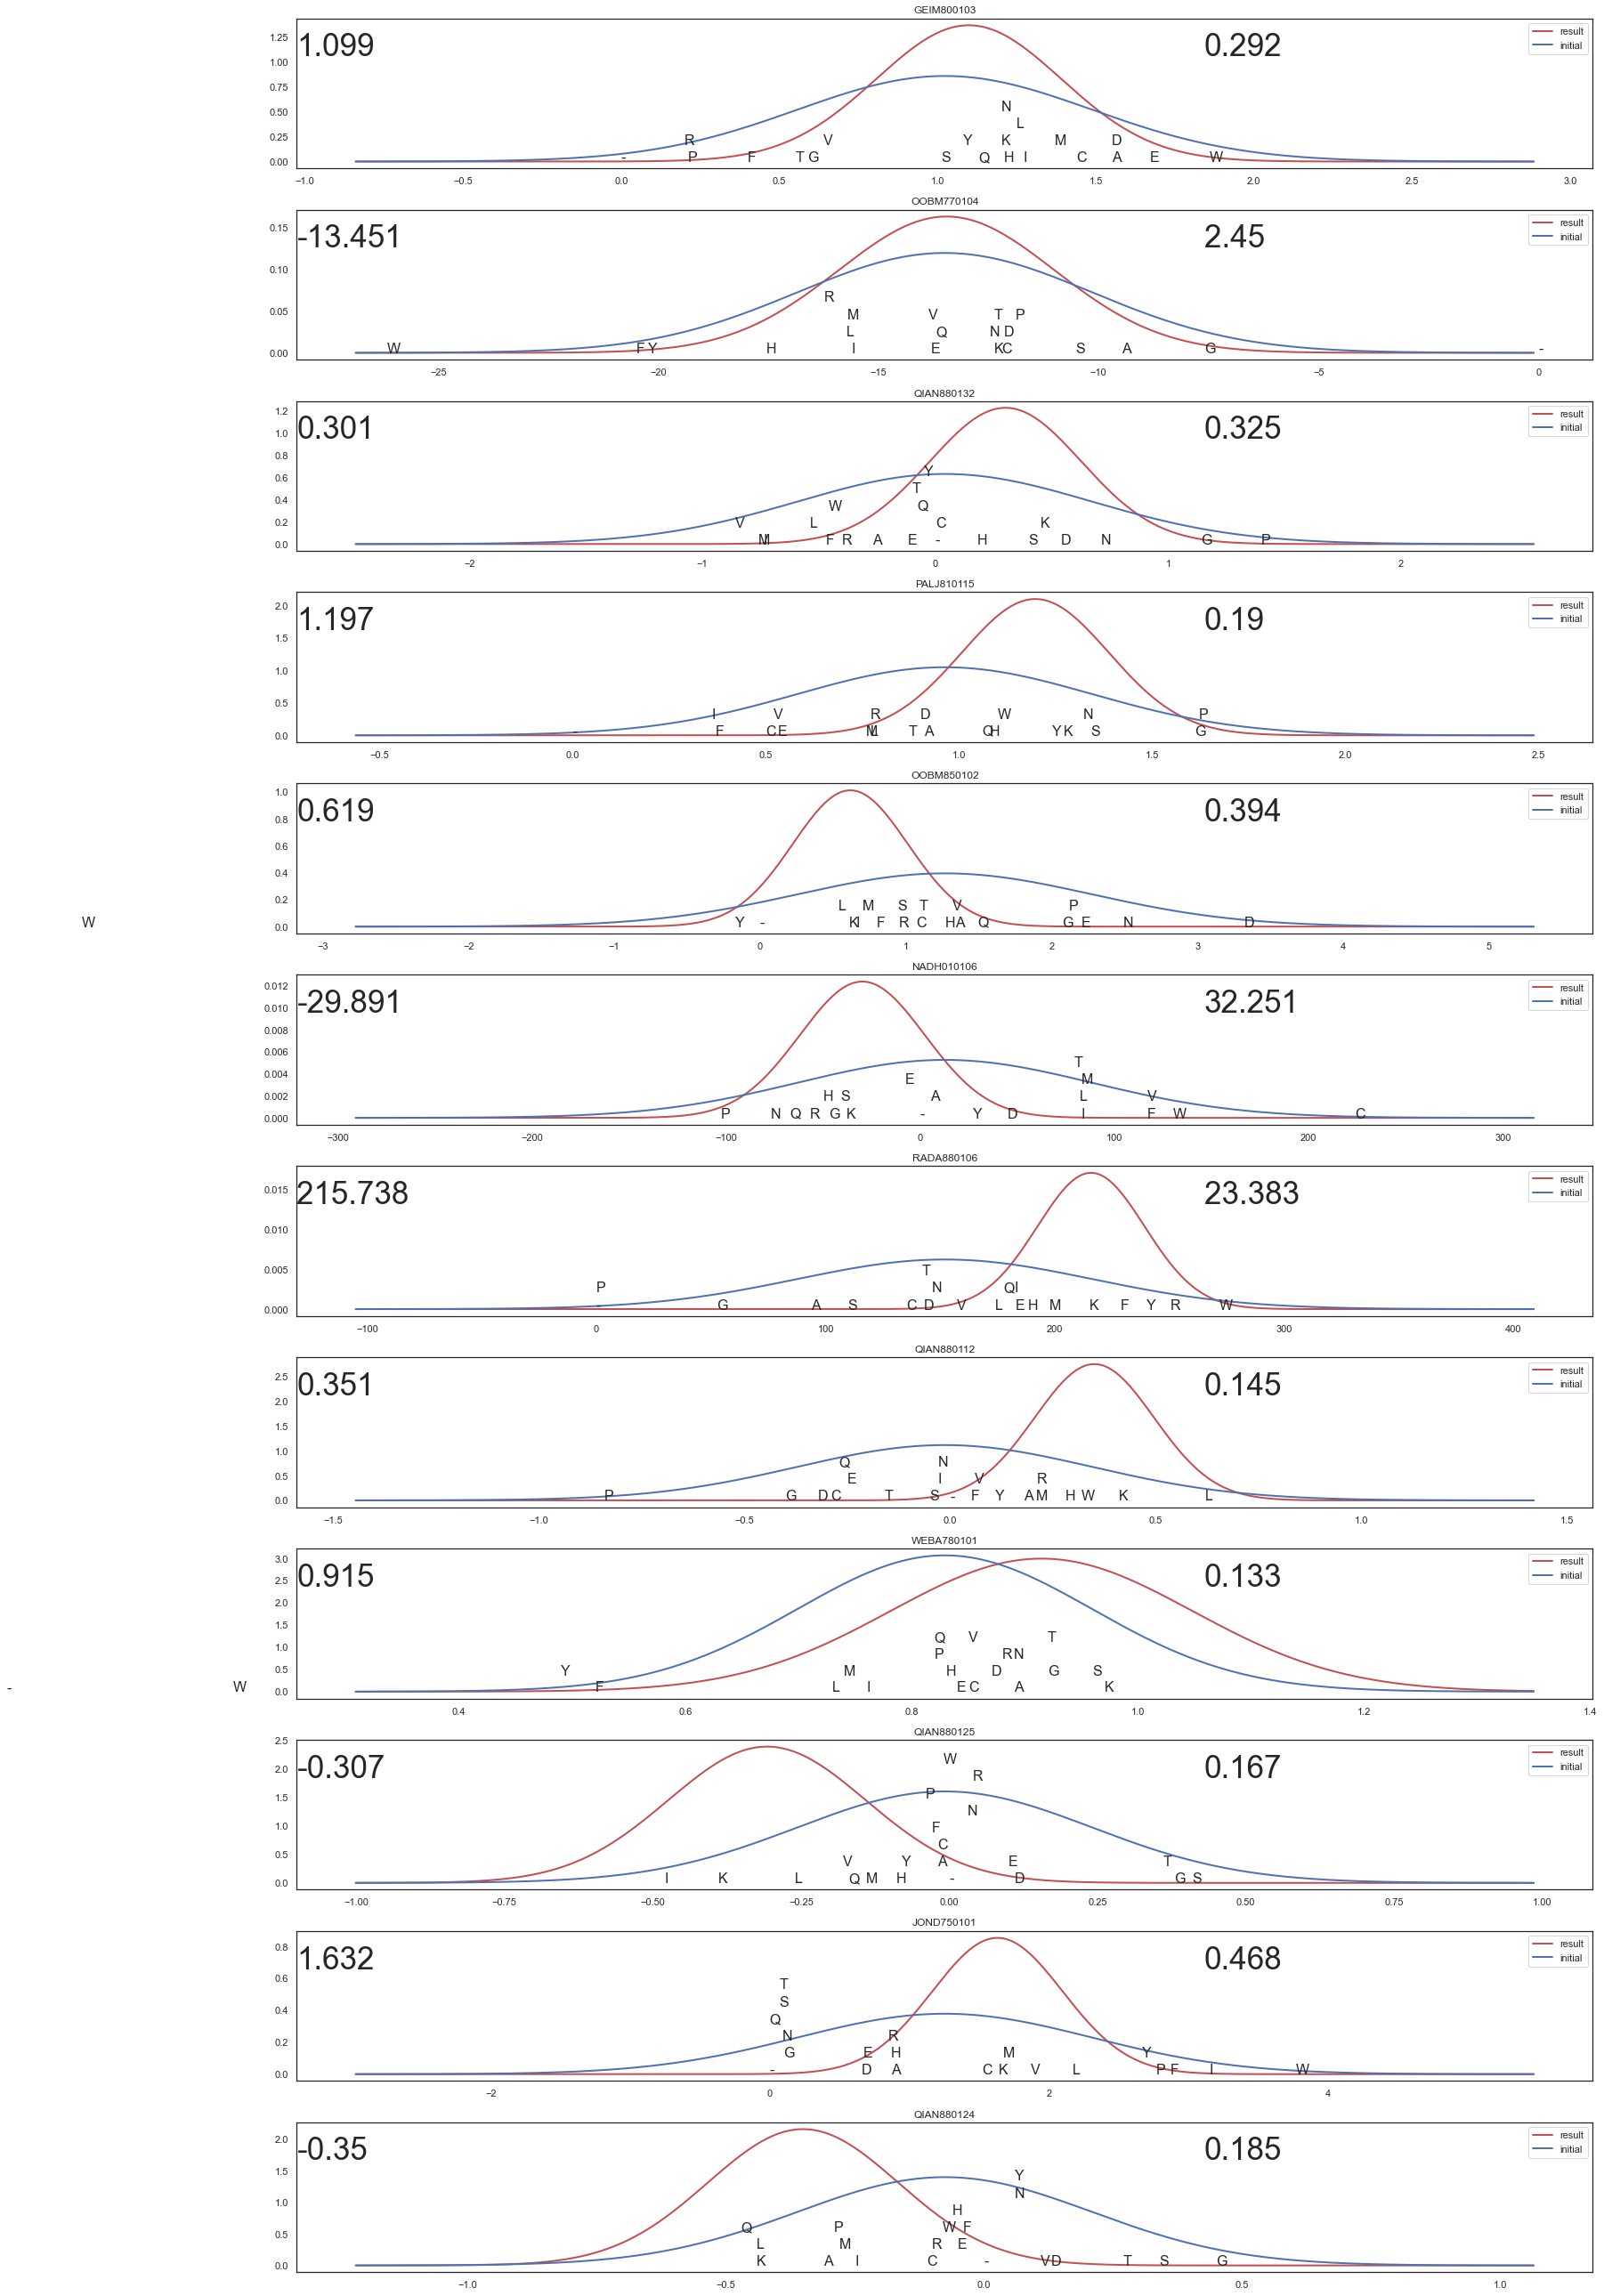

In [37]:
from collections import defaultdict
selected_state = model.states[8]
property_names = IMPORTANT_PROPERTIES_FROM_PAPER

list_of_dists = selected_state.distribution.parameters[0]
fig, axes = plt.subplots(ncols=1, nrows=len(list_of_dists), figsize=(25, len(list_of_dists)* 3))
for i, distr in enumerate(list_of_dists):
    ax = axes[i]
    inital_param_distr = initial_params[i]
    initial_mean = inital_param_distr['mean']
    initial_std =  inital_param_distr['std']
    initial_distr = NormalDistribution(initial_mean, initial_std)
    distr_params = distr.parameters
    mean_value = distr_params[0]
    std_value = distr_params[1]
    x = np.linspace(initial_mean-4*initial_std, initial_mean+4*initial_std, 1000)
    y1= norm.pdf(x, loc=mean_value, scale=std_value)
    y2 = norm.pdf(x, loc=initial_mean, scale=initial_std)
    axes[i].plot(x, y1, 'r', lw=2, label=f'result')
    axes[i].plot(x, y2, 'b', lw=2, label=f'initial')
    axes[i].text(0.0, 0.75, f'{np.round(mean_value,3)}', fontsize=35, transform=ax.transAxes)
    axes[i].text(0.7, 0.75, f'{np.round(std_value,3)}', fontsize=35, transform=ax.transAxes)

    transform_dict = transform_dicts[i]
    scale_value_y = max(y1)/8
    print(f"scale {scale_value_y}")
    scale_value_x = std_value/3
    aa_to_x_position = dict()
    x_position_bin_to_aa = defaultdict(list)
    for aa,prop_value in transform_dict.items():
        aa_to_x_position[aa] = prop_value
    aa_to_y_position = dict()
    for aa,x_pos in aa_to_x_position.items():
        x_position_bin_to_aa[int(x_pos/scale_value_x)].append(aa)
    for bin, aas in x_position_bin_to_aa.items():
        for j, aa in enumerate(aas):
            aa_to_y_position[aa] = scale_value_y*j
    for aa,prop_value in transform_dict.items():
        ax.text(aa_to_x_position[aa], aa_to_y_position[aa], aa, fontsize=16 )

    prob_dict = {aa: initial_distr.probability(value) for aa, value in transform_dict.items()}
    print("before", dict(sorted(prob_dict.items(), key=lambda item:item[1],reverse=True)[:5]))
    prob_dict = {aa: distr.probability(value) for aa, value in transform_dict.items()}
    print("after", dict(sorted(prob_dict.items(), key=lambda item:item[1],reverse=True)[:5]))
    ax.legend()
    ax.set_title(property_names[i])
plt.tight_layout()

In [10]:
IMPORTANT_PROPERTIES_FROM_PAPER

['GEIM800103',
 'OOBM770104',
 'QIAN880132',
 'PALJ810115',
 'OOBM850102',
 'NADH010106',
 'RADA880106',
 'QIAN880112',
 'WEBA780101',
 'QIAN880125',
 'JOND750101',
 'QIAN880124']

In [14]:
aaindex['QIAN880112']

{'category': 'sec_struct',
 'description': 'Weights for alpha-helix at the window position of 5 (Qian-Sejnowski, 1988)',
 'notes': '',
 'refs': "Qian, N. and Sejnowski, T.J. 'Predicting the secondary structure of globular proteins using neural network models' J. Mol. Biol. 202, 865-884 (1988); Kawashima, S. and Kanehisa, M.                     'AAindex: amino acid index database.'  Nucleic Acids Res. 28, 374 (2000).",
 'values': {'-': 0,
  'A': 0.18,
  'C': -0.29,
  'D': -0.32,
  'E': -0.25,
  'F': 0.05,
  'G': -0.4,
  'H': 0.28,
  'I': -0.03,
  'K': 0.41,
  'L': 0.62,
  'M': 0.21,
  'N': -0.03,
  'P': -0.84,
  'Q': -0.27,
  'R': 0.21,
  'S': -0.05,
  'T': -0.16,
  'V': 0.06,
  'W': 0.32,
  'Y': 0.11}}

In [59]:
from scipy.stats import binned_statistic
data = list(transform_dict.values())
bin_means = binned_statistic(data, data, bins=10, range=(min(data), max(data)))[0]


In [60]:
bin_means

array([-0.78666667, -0.49      , -0.335     , -0.05833333,  0.18      ,
        0.425     ,  0.625     ,         nan,  1.14      ,  1.4       ])

In [64]:
transform_dict.values()

dict_values([0, -0.27, 0.0, 0.54, -0.12, -0.47, 1.14, 0.18, -0.74, 0.45, -0.54, -0.76, 0.71, 1.4, -0.08, -0.4, 0.4, -0.1, -0.86, -0.46, -0.05])

In [139]:
bin_means

array([-0.78666667, -0.49      , -0.335     , -0.05833333,  0.18      ,
        0.425     ,  0.625     ,         nan,  1.14      ,  1.4       ])

In [114]:
transform_dicts[1]

{'-': 0,
 'A': -9.475,
 'C': -12.21,
 'D': -12.144,
 'E': -13.815,
 'F': -20.504,
 'G': -7.592,
 'H': -17.55,
 'I': -15.608,
 'K': -12.366,
 'L': -15.728,
 'M': -15.704,
 'N': -12.48,
 'P': -11.893,
 'Q': -13.689,
 'R': -16.225,
 'S': -10.518,
 'T': -12.369,
 'V': -13.867,
 'W': -26.166,
 'Y': -20.232}

In [141]:
peptides = model.sample(n=1000)

In [43]:
probs = pd.DataFrame({"index": [i for i in range(len(peptides))],"prob":[model.viterbi(peptide)[0]  for peptide in peptides]})
probs['len'] = [len(x) for x in peptides]
probs['norm_prob'] = probs['prob'] / probs['len']

Look at best peptide

In [44]:
probs

,index,prob,len,norm_prob
0,0,-57.842446,13,-4.449419
1,1,-39.278860,10,-3.927886
2,2,-38.337398,9,-4.259711
3,3,-41.937873,9,-4.659764
4,4,-59.979491,13,-4.613807
...,...,...,...,...
995,995,-41.988396,10,-4.198840
996,996,-66.674119,15,-4.444941
997,997,-40.495310,10,-4.049531
998,998,-52.144746,11,-4.740431


In [45]:
ten_best = probs.sort_values(by='norm_prob', ascending=False).head(10).index.values

In [46]:
ten_best

array([853, 349, 865, 514, 428,  82, 570, 605,  67, 203], dtype=int64)

In [47]:
per_allele_per_kfold_per_length_binders_train_old.keys()

dict_keys(['HLA-A*03:01', 'HLA-DRB1*04:01', 'HLA-A*01:01', 'HLA-DPA1*01:03-DPB1*04:01', 'HLA-DRB1*01:01', 'HLA-B*27:05', 'HLA-A*02:01', 'HLA-B*07:02'])

In [42]:
selected_allele = ALLELES[0]


In [51]:
correct_peptides_9_mers = per_allele_per_kfold_per_length_binders_train_old[selected_allele][0][9]
correct_peptides_9_mers_transformed = [np.array([tuple(transform_dict[aa] for transform_dict in transform_dicts) for aa in peptide]) for peptide in correct_peptides_9_mers]

correct_peptides_10_mers = per_allele_per_kfold_per_length_binders_train_old[selected_allele][0][10]
correct_peptides_10_mers_transformed = [np.array([tuple(transform_dict[aa] for transform_dict in transform_dicts) for aa in peptide]) for peptide in correct_peptides_10_mers]

correct_peptides_11_mers = per_allele_per_kfold_per_length_binders_train_old[selected_allele][0][11]
correct_peptides_11_mers_transformed = [np.array([tuple(transform_dict[aa] for transform_dict in transform_dicts) for aa in peptide]) for peptide in correct_peptides_11_mers]

correct_peptides_12_mers = per_allele_per_kfold_per_length_binders_train_old[selected_allele][0][12]
correct_peptides_12_mers_transformed = [np.array([tuple(transform_dict[aa] for transform_dict in transform_dicts) for aa in peptide]) for peptide in correct_peptides_12_mers]

In [52]:
correct_peptides_12_mers

array(['RLRPVNQNKTVK', 'GVVCPVSDILYK', 'VVLPLDERAFEK', 'KIMKVNYEQIVK',
       'RLLDMDGIIVEK', 'KSGDALRQSLSK', 'RQYAACEQRLGK', 'RLLDTLSDQIRK',
       'KMKEIAEAYLGK', 'RLATNTSAPDLK', 'KLYLLSSARMLK', 'KVANVSLLALYK',
       'RVFEEYEKIANK', 'RSYVTTSTRTYS', 'RIFGLLMGTLQK', 'KLLNLEHLKLLK',
       'ATYHANTEREQK', 'RMMLGKRSAILK', 'KVFDPVPVGVTK', 'KLIQEKKDNLLK',
       'RLRQIFNGTFVK', 'SVYVDAVGQFLK', 'PPYTVVYAARRT', 'AVYDPYKPYQLK',
       'ALFPLLPKVLQK', 'DAYVLPKLYVKL', 'VLYHYVAVNNPK', 'KLKDISTLEPLK',
       'ALFTPWKLSSQK', 'ALFLDKMGSLQK', 'RLWLRAGALLVK', 'KTIEEAKAIISK',
       'KVRPPVGGISVK', 'RLADKSVLVCKG', 'AIYELAVASFPK', 'RTWKGAVYGGFK',
       'RIRDQLSAVASK', 'LKFSPQALLLVK', 'AVILPPLSPYFK', 'AVLAVLAAAKSK',
       'SLYDQAEKLVSK', 'ATFRLKDGVLAY', 'TFTVTEKPEVID', 'SVKPSASASSPK',
       'SASSTYSSQLRK', 'ALFEISKYVMYK', 'KLWDLASGTLYK', 'RQGNFFASPMLK',
       'RVQPIKLARVTK', 'ATAASSSSLEKS', 'SLFYSTTVTLFK', 'KLAEAERVGLHK',
       'ILRELYGVGVEK', 'LITPAVVSERLK', 'ATISNDGATILK', 'KVKKPATAAGTK',
      

In [55]:
[">".join([path_node[1].name for path_node in model.viterbi(peptide)[1][1:-1]]) for peptide in correct_peptides_9_mers_transformed[:10]]

['s007>s000>s001>s002>s003>s004>s005>s006>s008',
 's007>s000>s001>s002>s003>s004>s005>s006>s008',
 's007>s000>s001>s002>s003>s004>s005>s006>s008',
 's007>s000>s001>s002>s003>s004>s005>s006>s008',
 's007>s000>s001>s002>s003>s004>s005>s006>s008',
 's007>s000>s001>s002>s003>s004>s005>s006>s008',
 's007>s000>s001>s002>s003>s004>s005>s006>s008',
 's007>s000>s001>s002>s003>s004>s005>s006>s008',
 's007>s000>s001>s002>s003>s004>s005>s006>s008',
 's007>s000>s001>s002>s003>s004>s005>s006>s008']

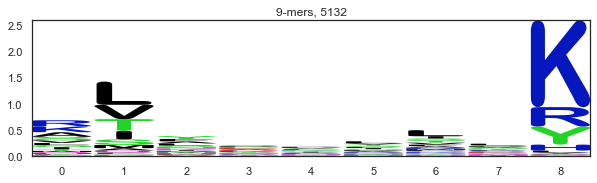

In [75]:
make_logo_for_data(correct_peptides_9_mers, "9-mers")

In [76]:
[">".join([path_node[1].name for path_node in model.viterbi(peptide)[1][1:-1]]) for peptide in
 correct_peptides_10_mers_transformed[:10]]


['s007>s000>s001>s002>s003>s004>s005>s006>s008>s010',
 's007>s000>s001>s002>s003>s004>s005>s006>s008>s010',
 's009>s007>s000>s001>s002>s003>s004>s005>s006>s008',
 's007>s000>s001>s002>s003>s004>s005>s006>s008>s010',
 's007>s000>s001>s002>s003>s004>s005>s006>s008>s010',
 's007>s000>s001>s002>s003>s004>s005>s006>s008>s010',
 's007>s000>s001>s002>s003>s004>s005>s006>s008>s010',
 's007>s000>s001>s002>s003>s004>s005>s006>s008>s010',
 's007>s000>s001>s002>s003>s004>s005>s006>s008>s010',
 's007>s000>s001>s002>s003>s004>s005>s006>s008>s010']

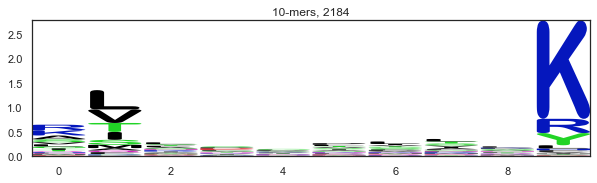

In [77]:
make_logo_for_data(correct_peptides_10_mers, "10-mers")

In [59]:
correct_peptides_10_mers

array(['WLWGFLSRNK', 'LIIGPMFSGK', 'ILLYPPTSTY', ..., 'LLYLNGVTKY',
       'KLREPNFTLK', 'KAEMQLKIDK'], dtype=object)

In [78]:
[">".join([path_node[1].name for path_node in model.viterbi(peptide)[1][1:-1]]) for peptide in
 correct_peptides_11_mers_transformed[:10]]


['s007>s000>s001>s002>s003>s004>s005>s006>s008>s010>s010',
 's007>s000>s001>s002>s003>s004>s005>s006>s008>s010>s010',
 's007>s000>s001>s002>s003>s004>s005>s006>s008>s010>s010',
 's007>s000>s001>s002>s003>s004>s005>s006>s008>s010>s010',
 's007>s000>s001>s002>s003>s004>s005>s006>s008>s010>s010',
 's007>s000>s001>s002>s003>s004>s005>s006>s008>s010>s010',
 's007>s000>s001>s002>s003>s004>s005>s006>s008>s010>s010',
 's007>s000>s001>s002>s003>s004>s005>s006>s008>s010>s010',
 's009>s007>s000>s001>s002>s003>s004>s005>s006>s008>s010',
 's009>s007>s000>s001>s002>s003>s004>s005>s006>s008>s010']

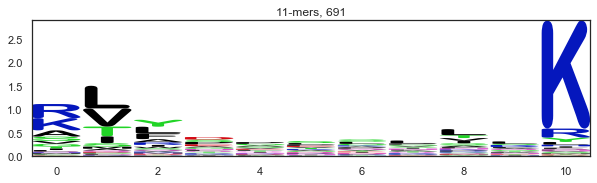

In [79]:
make_logo_for_data(correct_peptides_11_mers, "11-mers")

In [80]:
[">".join([path_node[1].name for path_node in model.viterbi(peptide)[1][1:-1]]) for peptide in
 correct_peptides_12_mers_transformed[:10]]

['s007>s000>s001>s002>s003>s004>s005>s006>s008>s010>s010>s010',
 's007>s000>s001>s002>s003>s004>s005>s006>s008>s010>s010>s010',
 's007>s000>s001>s002>s003>s004>s005>s006>s008>s010>s010>s010',
 's007>s000>s001>s002>s003>s004>s005>s006>s008>s010>s010>s010',
 's007>s000>s001>s002>s003>s004>s005>s006>s008>s010>s010>s010',
 's007>s000>s001>s002>s003>s004>s005>s006>s008>s010>s010>s010',
 's007>s000>s001>s002>s003>s004>s005>s006>s008>s010>s010>s010',
 's007>s000>s001>s002>s003>s004>s005>s006>s008>s010>s010>s010',
 's007>s000>s001>s002>s003>s004>s005>s006>s008>s010>s010>s010',
 's007>s000>s001>s002>s003>s004>s005>s006>s008>s010>s010>s010']

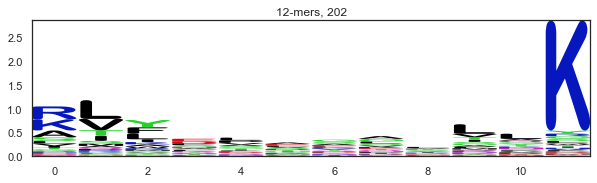

In [81]:
make_logo_for_data(correct_peptides_12_mers, "12-mers")

In [54]:
transform_dicts

[{'-': 0,
  'A': 1.55,
  'C': 1.44,
  'D': 1.55,
  'E': 1.67,
  'F': 0.4,
  'G': 0.59,
  'H': 1.21,
  'I': 1.27,
  'K': 1.2,
  'L': 1.25,
  'M': 1.37,
  'N': 1.2,
  'P': 0.21,
  'Q': 1.13,
  'R': 0.2,
  'S': 1.01,
  'T': 0.55,
  'V': 0.64,
  'W': 1.86,
  'Y': 1.08},
 {'-': 0,
  'A': -9.475,
  'C': -12.21,
  'D': -12.144,
  'E': -13.815,
  'F': -20.504,
  'G': -7.592,
  'H': -17.55,
  'I': -15.608,
  'K': -12.366,
  'L': -15.728,
  'M': -15.704,
  'N': -12.48,
  'P': -11.893,
  'Q': -13.689,
  'R': -16.225,
  'S': -10.518,
  'T': -12.369,
  'V': -13.867,
  'W': -26.166,
  'Y': -20.232},
 {'-': 0,
  'A': -0.27,
  'C': 0.0,
  'D': 0.54,
  'E': -0.12,
  'F': -0.47,
  'G': 1.14,
  'H': 0.18,
  'I': -0.74,
  'K': 0.45,
  'L': -0.54,
  'M': -0.76,
  'N': 0.71,
  'P': 1.4,
  'Q': -0.08,
  'R': -0.4,
  'S': 0.4,
  'T': -0.1,
  'V': -0.86,
  'W': -0.46,
  'Y': -0.05}]

In [55]:
np_peptides = np.array(peptides, dtype=object)

In [56]:
np_peptides

array([array([[  0.94739959, -13.93544771,   0.3904932 ],
              [  0.37729922, -11.4455297 ,  -0.85969121],
              [  0.90810217, -15.11091992,   1.0099946 ],
              [  0.92545631, -16.23356463,   0.21997248],
              [  1.81560354,  -8.5322738 ,   0.78350835],
              [  0.3691724 ,  -8.81835858,  -0.39795866],
              [  1.68442083,  -9.31735836,   0.50219011],
              [  1.34880616,  -9.77326076,  -0.26146788],
              [  1.18547494, -13.76957011,  -0.24403975],
              [  0.96610317, -15.60171634,   0.3461068 ],
              [  1.2351205 , -10.39317324,  -0.29602808],
              [  1.11305322, -14.60485405,   0.37748337],
              [  0.98593645,  -6.74480903,  -0.64874952]]),
       array([[  0.83977582, -14.00175964,  -0.28303689],
              [  0.68833296, -12.87633291,  -0.69881296],
              [  1.23194975, -18.05600516,   0.26162419],
              [  1.39764239, -11.95294968,   0.2487496 ],
            

In [308]:
per_aa_properties = defaultdict(list)

In [309]:
for transform_dict in transform_dicts:
    for aa, prop_value in transform_dict.items():
        per_aa_properties[aa].append(prop_value)


In [310]:
per_aa_properties = {aa: np.array(prop_vector) for aa, prop_vector in per_aa_properties.items()}

In [311]:
del per_aa_properties['-']

In [312]:
aa_vectors = pd.DataFrame(per_aa_properties).T
aa_vectors

,0,1,2,3,4,5,6,7,8,9,10,11
A,1.55,-9.475,-0.27,0.91,1.34,5.0,93.7,0.18,0.89,-0.02,0.87,-0.31
C,1.44,-12.210,0.00,0.50,1.07,224.0,135.2,-0.29,0.85,-0.02,1.52,-0.11
D,1.55,-12.144,0.54,0.90,3.32,45.0,142.6,-0.32,0.87,0.11,0.66,0.13
E,1.67,-13.815,-0.12,0.53,2.20,-8.0,182.9,-0.25,0.84,0.10,0.67,-0.05
F,0.40,-20.504,-0.47,0.37,0.80,117.0,228.6,0.05,0.52,-0.03,2.87,-0.04
G,0.59,-7.592,1.14,1.61,2.07,-47.0,52.6,-0.40,0.92,0.38,0.10,0.45
H,1.21,-17.550,0.18,1.08,1.27,-50.0,188.1,0.28,0.83,-0.09,0.87,-0.06
I,1.27,-15.608,-0.74,0.36,0.66,83.0,182.2,-0.03,0.76,-0.48,3.15,-0.25
K,1.20,-12.366,0.45,1.27,0.61,-38.0,215.2,0.41,0.97,-0.39,1.64,-0.44
L,1.25,-15.728,-0.54,0.77,0.54,82.0,173.7,0.62,0.73,-0.26,2.17,-0.44


In [409]:
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import Normalizer
scaler = StandardScaler(with_std=False, with_mean=False)
scaler.fit(aa_vectors)

StandardScaler(with_mean=False, with_std=False)

In [410]:
peptide = model.sample()
peptide

array([[ 8.27554160e-01, -1.45271650e+01, -6.98202776e-01,
         8.42702939e-01,  1.63615133e-01, -1.56594660e+01,
         2.13261095e+02,  3.58166703e-02,  8.17797324e-01,
         3.47195226e-01,  1.55410374e+00, -2.35792174e-03],
       [ 5.55764378e-01, -1.55181449e+01, -9.30797222e-01,
         5.14930187e-01,  5.33108377e-01,  6.97250823e+01,
         2.03952145e+02, -4.65968930e-01,  9.27565180e-01,
        -3.90332098e-01,  1.87291133e+00,  1.57741966e-01],
       [ 1.41332135e+00, -1.69400795e+01, -5.15201427e-01,
         1.55148490e+00,  9.02818377e-01,  4.19163948e+01,
         1.98686324e+02, -1.08734819e-01,  6.23871444e-01,
        -8.12066131e-03,  2.06867562e+00, -3.41180839e-01],
       [ 9.26102620e-01, -1.27820764e+01,  1.66895395e-01,
         7.80385419e-01,  5.83948410e-01,  8.37278983e+01,
         7.19940930e+01, -9.10495402e-03,  7.59038022e-01,
         2.41729596e-01,  4.98670068e-01,  7.08746841e-02],
       [ 2.06382920e-02, -1.00474498e+01, -1.0130215

In [411]:
from scipy.spatial import distance

recovered_peptide = list()
for sampled_prop_vector in peptide:
    distance_dict = dict()
    sampled_prop_vector = scaler.transform(sampled_prop_vector.reshape(1,-1))
    for aa, aa_prop_vector in per_aa_properties.items():
        aa_prop_vector = scaler.transform(aa_prop_vector.reshape(1,-1))
        distance_dict[aa] = distance.euclidean(sampled_prop_vector, aa_prop_vector)
    aa = min(distance_dict.items(), key=lambda x:x[1])[0]
    recovered_peptide.append(aa)
    print(distance_dict)
    print(aa)

{'A': 121.4496216018736, 'C': 252.06669715387432, 'D': 93.22695067079633, 'E': 31.419525531236694, 'F': 133.6875683768711, 'G': 163.86730028716002, 'H': 42.71312049626469, 'I': 103.45833515124606, 'K': 22.589243425481243, 'L': 105.38279044963242, 'M': 99.9064660344993, 'N': 90.8881706270703, 'P': 230.49359223535035, 'Q': 62.50135649984168, 'R': 55.61439516554531, 'S': 106.90660262328942, 'T': 118.45924688161088, 'V': 144.0267712101067, 'W': 157.43391099683308, 'Y': 50.638957584485}
K
{'A': 128.0054849831411, 'C': 168.9403995887669, 'D': 66.32958579944322, 'E': 80.58377321896688, 'F': 53.565078401317905, 'G': 191.32882047576908, 'H': 120.80458570387168, 'I': 25.534239263746606, 'K': 108.3753752876748, 'L': 32.68471562056839, 'M': 14.77076050424843, 'N': 157.7098325223733, 'P': 267.30908015599533, 'Q': 139.25708516603595, 'R': 134.9798269399017, 'S': 145.64743401102533, 'T': 62.66318945327323, 'V': 66.51592085579756, 'W': 91.41526994411234, 'Y': 56.06457416977441}
M
{'A': 111.54796897978

In [412]:
recovered_peptide

['K', 'M', 'M', 'T', 'D', 'M', 'M', 'E', 'F', 'D', 'N']

In [425]:
selected_length = 10
sampled_peptides = model.sample(n=30000)

In [426]:
probs = pd.DataFrame({"index": [i for i in range(len(sampled_peptides))],"prob":[model.viterbi(peptide)[0]  for peptide in sampled_peptides]})
probs['len'] = [len(x) for x in sampled_peptides]
probs['norm_prob'] = probs['prob'] / probs['len']

probs = probs[probs.len == selected_length].sort_values(by='norm_prob', ascending=False)


In [427]:
probs.len.value_counts()

10    9425
Name: len, dtype: int64

In [428]:

sampled_peptides = np.array(sampled_peptides, dtype=object)
selected_peptides = sampled_peptides[probs.head(2000).index.values]

In [429]:
reverse_transformed_peptides = list()
for sampled_peptide in selected_peptides:
    recovered_peptide = list()
    for sampled_prop_vector in sampled_peptide:

        distance_dict = dict()
        sampled_prop_vector = scaler.transform(sampled_prop_vector.reshape(1,-1))
        for aa, aa_prop_vector in per_aa_properties.items():
            aa_prop_vector = scaler.transform(aa_prop_vector.reshape(1,-1))
            distance_dict[aa] = distance.euclidean(sampled_prop_vector, aa_prop_vector)
        aa = min(distance_dict.items(), key=lambda x:x[1])[0]
        recovered_peptide.append(aa)
    reverse_transformed_peptides.append("".join(recovered_peptide))


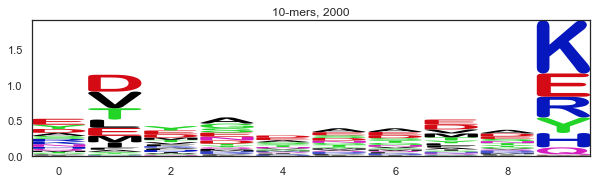

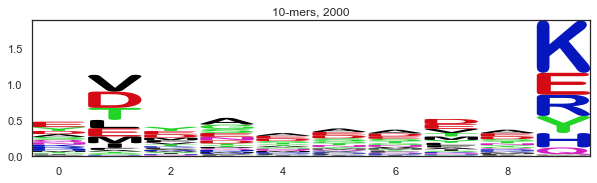

In [430]:
import logomaker
make_logo_for_data(reverse_transformed_peptides, f"{selected_length}-mers")

In [431]:
reverse_transformed_peptides

['QTYQEHDEEK',
 'DLMGVNFIDY',
 'KVAHQGEMNE',
 'HDEDNEHISE',
 'NVKHGEAYDE',
 'KLYGGLGMTE',
 'NLIPSDTAEK',
 'KMYAEDYILK',
 'QDKEQQSEEK',
 'SVTPAMDFMY',
 'KMDDFSTDAE',
 'ALANEVQEVR',
 'YDYGDDLTYY',
 'DDIPKEMLTE',
 'QDTDGDLDCE',
 'RDESVSYIIY',
 'VTYEAEEFHK',
 'NVVGAEAEYR',
 'HMYNAEDEQK',
 'RVLYGTAYEE',
 'EVTMNDQYRE',
 'LDENETMVHK',
 'HDAYSNDDAE',
 'EFTAQYVVDR',
 'KTAGRSDSDK',
 'EDSAEGDYAK',
 'YTMPSSEDDY',
 'FLFDDATCAK',
 'HYHAAESTAY',
 'RLYHDQTFLR',
 'EDYEHSAYYK',
 'ETHSSTATKY',
 'YETADDVVEE',
 'KIAEKKLKKR',
 'YDYASEADHH',
 'YMTWIDDEDK',
 'GYESCQATEH',
 'DVKYESYHDY',
 'YIMHMAFTDK',
 'MLDANESVHK',
 'HERSTQVMTR',
 'YESSKEGLVH',
 'NDDESMDLMK',
 'ETKDCGEESK',
 'QVYADNTANK',
 'ETEEEEGEIK',
 'QVVNVGMEQR',
 'EEFEQTADAK',
 'QDASALPDNK',
 'QDASALPDNK',
 'REDFHNSCSK',
 'QDVSNSVHWK',
 'EDDEEAVTER',
 'KTVTAMSTHK',
 'SDDKYAEMDH',
 'SEARKAMMEE',
 'ESTATNDLAH',
 'IDEKMSMDAR',
 'IDEKMSMDAR',
 'DMDGGLELFK',
 'DMYAATSDAE',
 'RVDNVEHMEE',
 'NTEEVAMFLE',
 'LIESHSMTSK',
 'RLIYRETEDH',
 'YVLAGEGMRR',
 'NADRNATV

In [353]:
property = 2


transform_dict = transform_dicts[property].copy()
del transform_dict['-']
for sampled_peptide in model.sample(n=10000):
    peptide = []
    for sampled_value in sampled_peptide[:, property]:
        distance_dict = {key: abs(value - sampled_value) for key, value in transform_dict.items()}
        peptide.append(min(distance_dict, key=distance_dict.get))
    reverse_transformed_peptides.append("".join(peptide))

In [114]:
reverse_transformed_peptides

['CRGTASHAVWASHCVSR',
 'ARVVKSDVNV',
 'HHENGVVSVL',
 'VAHNVGDALC',
 'QRLDRCCTEDAV',
 'CMRDSGIRW',
 'LACRCGILLD',
 'KGRIAAYHVCVA',
 'HHCGRECVWCRKN',
 'CCIRMSPHHCVHAH',
 'AMHGSVHSH',
 'HASLHSNKH',
 'HWNNCRCSV',
 'SVHEHGHHECC',
 'ATPCDHHASN',
 'VANDIEEVNNADAR',
 'CCYAHVDIH',
 'NMNDDSWMPQKICGY',
 'NDKAYAPSSIIL',
 'CGSLANEVSED',
 'CFWPCDHPKA',
 'CGIKAHSDACL',
 'VEAPCKHGLA',
 'CAYSCIVVV',
 'AMHENNHPSRC',
 'WILPNDRYAH',
 'VRHICVSPVC',
 'DIHDDVDVYH',
 'SVVHNLVCEAVEH',
 'GWYICRCHHR',
 'TAVDHHHHND',
 'SHRMHDKVYFY',
 'LCVQMDDNKSH',
 'CCHSASLYMRH',
 'LIINQCSALH',
 'LAHNSVVDCG',
 'KCIFGHEHANV',
 'VVKLPHQMHNCGV',
 'HGLIVHHPDNVERC',
 'NWLALQTVASVGK',
 'CIWGPWEVCA',
 'ALDFPLVQN',
 'DLMDIIQVN',
 'RHNDVNRDKHICH',
 'SRCGLSSDHNGVHIKS',
 'GRWKTNVRVQP',
 'HSSLENSCSIEH',
 'AVMDHRDNAGS',
 'FHHCKQDCN',
 'RLASRSVSN',
 'IICLQVCEWAE',
 'WRAGSIGNSADE',
 'RVTHHAKIAND',
 'HVHDDEVIHIL',
 'HHIISSAVHEHS',
 'DTNSCLQDR',
 'AESYCIWAAIS',
 'RHHLRRNNSCNCR',
 'GVHTEAANCVCPA',
 'CRVPAPHVNI',
 'ENRCDDLCRLC',
 'AVESWNNAYV',
 'L

In [115]:
df_reverse = pd.DataFrame({"peptide": reverse_transformed_peptides})

In [116]:
df_reverse['len'] = df_reverse.peptide.str.len()

In [117]:
df_reverse.len.value_counts()

10    3016
11    2127
9     1808
12    1368
13     782
14     442
15     217
16     101
17      70
18      38
19      18
20       8
23       2
24       2
21       1
Name: len, dtype: int64

In [118]:
selected_length = 9
peptides_for_motif = df_reverse[df_reverse['len'] == selected_length]['peptide'].values

In [119]:
peptides_for_motif[:10]

array(['CMRDSGIRW', 'AMHGSVHSH', 'HASLHSNKH', 'HWNNCRCSV', 'CCYAHVDIH',
       'CAYSCIVVV', 'ALDFPLVQN', 'DLMDIIQVN', 'FHHCKQDCN', 'RLASRSVSN'],
      dtype=object)

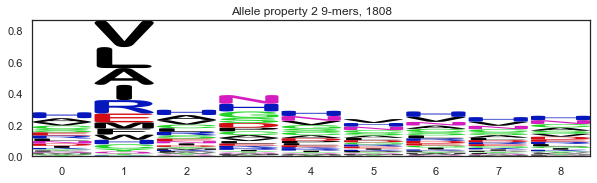

In [156]:
min(transform_dicts[0].items(), key=lambda (key, value) :abs(x-value))

SyntaxError: invalid syntax (Temp/ipykernel_12296/2630203387.py, line 1)

In [149]:
best_peptide

array([[  1.39630017, -16.55327495,  -0.50517585],
       [  0.62983504, -17.32035868,  -0.04732805],
       [  1.25262103, -15.27089694,   0.22294073],
       [  1.23978008, -12.11114207,  -0.73748807],
       [  1.11034866, -14.78909163,  -0.44471221],
       [  1.50580789, -12.86561112,   0.5618994 ],
       [  1.31368093, -12.06770185,  -0.24385359],
       [  1.15146528, -15.90527935,  -0.43256495],
       [  1.82034438, -12.18436169,   0.84763509],
       [  0.87271453, -16.55206062,  -0.02321879],
       [  1.17151958, -13.00875451,   0.67231885]])

In [143]:
train_peptide = correct_peptides_transformed[1]

In [148]:
correct_peptides[1]

'KLATSVLAGLLGVVS'

<AxesSubplot:>

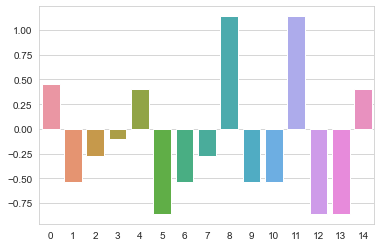

In [144]:
sns.barplot(x=np.arange(0, len(train_peptide)), y=train_peptide[:, 2])

<AxesSubplot:>

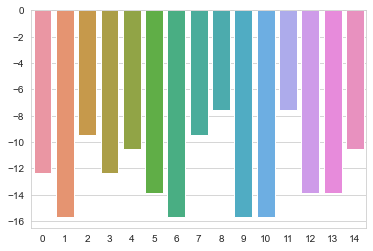

In [145]:
sns.barplot(x=np.arange(0, len(train_peptide)), y=train_peptide[:, 1])

<AxesSubplot:>

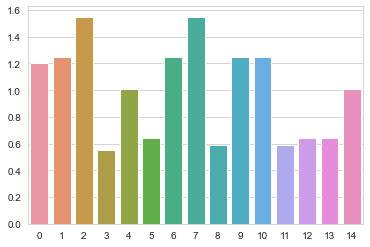

In [146]:
sns.barplot(x=np.arange(0, len(train_peptide)), y=train_peptide[:, 0])

In [69]:
np.sum(ten_best_peptides, axis=0)

ValueError: operands could not be broadcast together with shapes (11,3) (10,3) 

In [38]:
peptide

array([[  1.39125768, -18.21882837,   0.14343468],
       [  1.27708304, -12.11991018,  -0.12214817],
       [  0.67135385, -24.91573046,  -0.35113952],
       [  0.67629342, -13.39393235,  -0.75467282],
       [  0.84934097, -17.00151845,  -0.21059953],
       [  1.49461083, -15.80499407,  -0.49082834],
       [  2.40277322, -14.24836669,  -0.39752995],
       [  0.99209309, -10.05710951,   0.45446181],
       [  0.83780578, -17.49903151,  -0.5932868 ],
       [  0.9122496 , -13.12360981,   0.97000934],
       [  1.39638222, -12.20867203,   0.21481616],
       [  0.67551882, -15.88611363,  -0.49447582]])

In [43]:
allele_peptides = np.concatenate([per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][target_length] for target_length in TARGET_LENGTHS])

In [159]:
ALLELES

['HLA-DPA1*01:03-DPB1*04:01', 'HLA-DRB1*01:01']

In [189]:
peptide = allele_peptides[5]
peptide

'SEAYLVGLFEDTN'

In [395]:
result = model.sample(n=1000, path=True)

C:\Users\Denis\AppData\Local\Temp/ipykernel_524/1975844636.py:1: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  result = model.sample(n=1000, path=True)


In [401]:
max_prob = -2000
max_path = None
max_peptide = None
for peptide, path in result:
    prob, viterbi_path = model.viterbi(peptide)
    prob = prob / len(peptide)
    if prob > max_prob:
        max_prob = prob
        max_path = path
        max_peptide = peptide

In [402]:
max_prob

-4.51326669648934

In [403]:
np.array(max_peptide)

array([[  0.77854669, -13.48282057,  -0.12539222],
       [  0.68272319, -10.01034668,   0.45376615],
       [  1.11036063, -13.41180047,   0.07183059],
       [  1.43216508, -15.12568617,  -0.17483103],
       [  0.8247562 , -13.89272745,  -0.75090236],
       [  0.40071125, -10.18791148,   0.07350749],
       [  1.47000848, -10.31069451,  -0.02101558],
       [  1.21072014, -15.18928383,  -0.62101386],
       [  1.35362278, -13.5447453 ,  -0.17876816],
       [  0.48538224, -12.09842882,   0.861933  ],
       [  0.78798226, -11.34902157,   0.20948479],
       [  1.37750587, -18.45099161,  -0.49834661],
       [  1.08685715, -14.84568831,   0.63004817],
       [  1.08354241, -13.90456608,  -0.21236269]])

In [190]:
print([item[1].name for item in model.viterbi(peptide)[1]])

['grouped_model-start', 's027', 's027', 's025', 's004', 's005', 's008', 's012', 's016', 's017', 's021', 's022', 's026', 's028', 'grouped_model-end']


In [ ]:
NGFKTQHFV

In [50]:
model.graph.edges()[cycle_state, cycle_state]

{'probability': -1.2327600919633284, 'pseudocount': 8000, 'group': None}